# 03 · Feature Engineering
Ordinal encoding → new features → skew correction → one-hot. Output → `data/processed/X_train.csv`, `X_test.csv`, `y.csv`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from scipy.special import boxcox1p

tr = pd.read_csv('../data/processed/clean_train.csv', keep_default_na=False)   # keep_default_na: stop pandas turning the string 'None' into NaN
te = pd.read_csv('../data/processed/clean_test.csv', keep_default_na=False)
for d in (tr, te):
    for c in ['MSSubClass','MoSold','YrSold']: d[c] = d[c].astype(str)
y = tr.pop('LogSalePrice'); test_ids = te.pop('Id'); n_train = len(tr)
df = pd.concat([tr, te], ignore_index=True); df.shape

(2917, 78)

## 3.1 Ordinal encoding
Quality-style columns have a real order (Po < Fa < TA < Gd < Ex). Encoding that order as integers keeps information one-hot would throw away.

In [2]:
QUAL = {'None':0,'Po':1,'Fa':2,'TA':3,'Gd':4,'Ex':5}
BSMT = {'None':0,'Unf':1,'LwQ':2,'Rec':3,'BLQ':4,'ALQ':5,'GLQ':6}
ORD = {**{c: QUAL for c in ['ExterQual','ExterCond','BsmtQual','BsmtCond','HeatingQC','KitchenQual',
                            'FireplaceQu','GarageQual','GarageCond','PoolQC']},
 'BsmtExposure':{'None':0,'No':1,'Mn':2,'Av':3,'Gd':4}, 'BsmtFinType1':BSMT, 'BsmtFinType2':BSMT,
 'GarageFinish':{'None':0,'Unf':1,'RFn':2,'Fin':3},
 'Functional':{'Sal':0,'Sev':1,'Maj2':2,'Maj1':3,'Mod':4,'Min2':5,'Min1':6,'Typ':7},
 'LotShape':{'IR3':0,'IR2':1,'IR1':2,'Reg':3}, 'LandSlope':{'Sev':0,'Mod':1,'Gtl':2},
 'PavedDrive':{'N':0,'P':1,'Y':2}, 'Fence':{'None':0,'MnWw':1,'GdWo':2,'MnPrv':3,'GdPrv':4},
 'CentralAir':{'N':0,'Y':1}}
for c, m in ORD.items(): df[c] = df[c].map(m).astype(int)

## 3.2 New features
Buyers think in totals (total area, total bathrooms, age), not in 20 separate columns.

In [3]:
df['TotalSF']      = df.TotalBsmtSF + df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath']    = df.FullBath + .5*df.HalfBath + df.BsmtFullBath + .5*df.BsmtHalfBath
df['TotalPorchSF'] = df.OpenPorchSF + df.EnclosedPorch + df['3SsnPorch'] + df.ScreenPorch + df.WoodDeckSF
df['HouseAge']     = (df.YrSold.astype(int) - df.YearBuilt).clip(lower=0)
df['RemodAge']     = (df.YrSold.astype(int) - df.YearRemodAdd).clip(lower=0)
df['IsRemodeled']  = (df.YearRemodAdd != df.YearBuilt).astype(int)
df['IsNew']        = (df.YrSold.astype(int) == df.YearBuilt).astype(int)
for name, col in [('HasPool','PoolArea'),('Has2ndFlr','2ndFlrSF'),('HasGarage','GarageArea'),
                  ('HasBsmt','TotalBsmtSF'),('HasFireplace','Fireplaces')]:
    df[name] = (df[col] > 0).astype(int)
df['QualxSF']   = df.OverallQual * df.TotalSF
df['QualxCond'] = df.OverallQual * df.OverallCond

check = df.iloc[:n_train].assign(y=y.values)
check[['TotalSF','TotalBath','HouseAge','QualxSF','OverallQual','GrLivArea','y']].corr()['y'].sort_values(ascending=False)

y              1.000000
QualxSF        0.882919
TotalSF        0.825326
OverallQual    0.821405
GrLivArea      0.725211
TotalBath      0.676678
HouseAge      -0.587767
Name: y, dtype: float64

## 3.3 Skew correction (Box-Cox, λ=0.15)
Linear models assume roughly symmetric features. Binary/ordinal-few columns are skipped.

In [4]:
num = df.select_dtypes(include=[np.number]).columns
sk = df[num].apply(skew); skewed = [c for c in sk[sk.abs()>0.75].index if df[c].nunique()>2]
print(len(skewed), 'skewed columns; before/after for LotArea:', round(skew(df.LotArea),2), end=' → ')
for c in skewed: df[c] = boxcox1p(df[c], 0.15)
print(round(skew(df.LotArea),2))

37 skewed columns; before/after for LotArea: 13.11 → 0.18


## 3.4 One-hot encode & drop ultra-rare dummies

In [5]:
df = pd.get_dummies(df, drop_first=True, dtype=int)
df = df.loc[:, df.sum() >= 5]          # a dummy that's 1 for <5 houses can't be learned
print('Final feature matrix:', df.shape)

X_train, X_test = df.iloc[:n_train], df.iloc[n_train:]
X_train.to_csv('../data/processed/X_train.csv', index=False)
X_test.assign(Id=test_ids.values).to_csv('../data/processed/X_test.csv', index=False)
y.to_csv('../data/processed/y.csv', index=False)

Final feature matrix: (2917, 221)


## 3.5 Quick check: which new features matter?

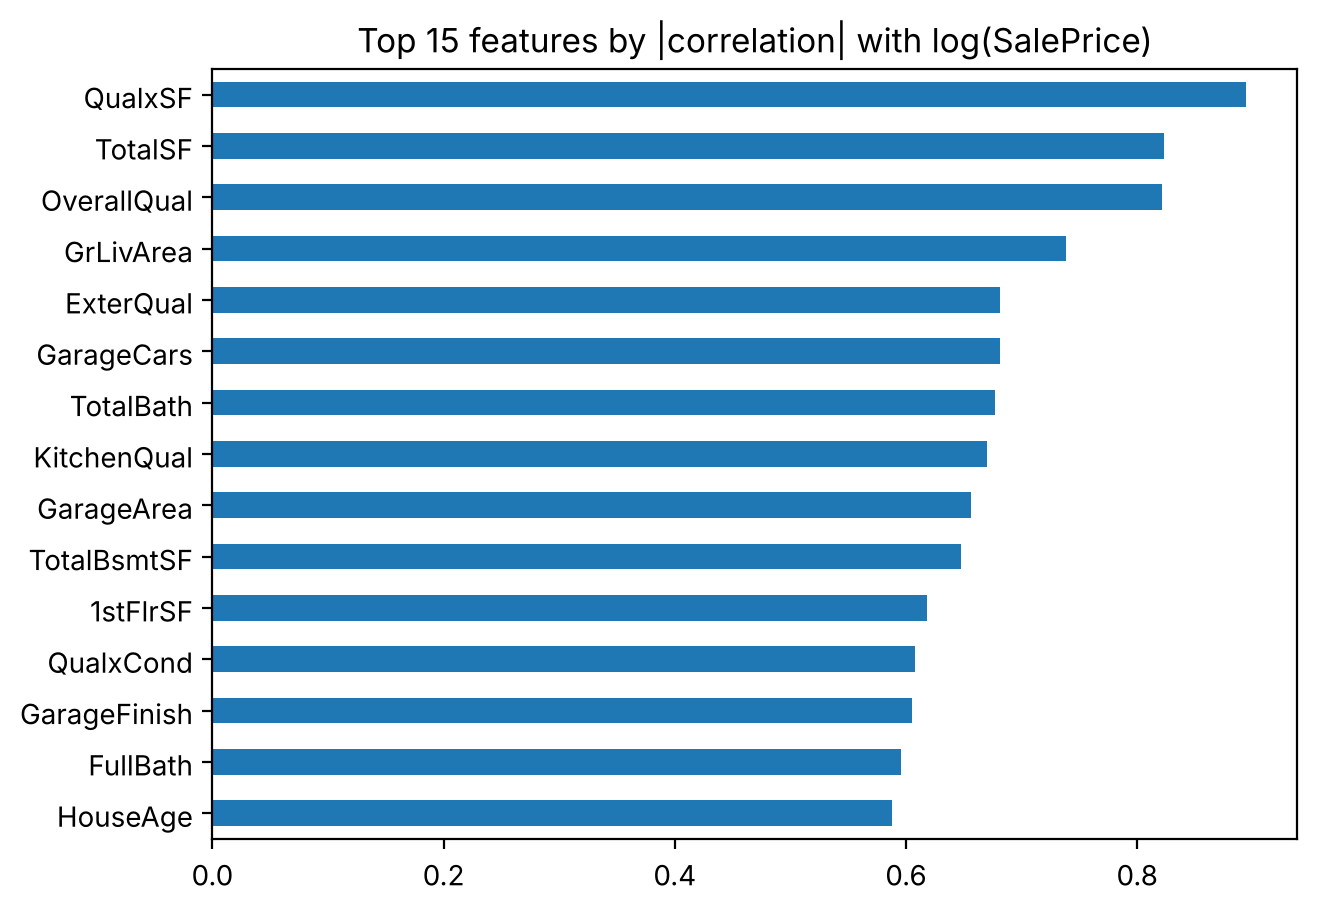

In [6]:
top = X_train.assign(y=y.values).corr()['y'].drop('y').abs().sort_values(ascending=False).head(15)
top.sort_values().plot.barh(figsize=(7,5), title='Top 15 features by |correlation| with log(SalePrice)'); plt.show()